# Einflussfaktoren auf den Mietpreis

**Ziel:** Abschätzen, welche Wohnungsmerkmale und Gemeindeindikatoren wie stark mit dem Mietpreis zusammenhängen (Research Question 1 und 2).

**Daten:**
- `data/data_processed/flatfox_rentals_clean.csv` – bereinigte Mietwohnungen mit Nettomiete und Gemeindeindikatoren (erzeugt in `data_cleaning_rentals.ipynb` aus `flatfox_rentals_zentralschweiz.csv`)
- `data/data_processed/gemeinde_indikatoren_zentralschweiz.csv` – alle 157 Gemeinden der Zentralschweiz (erzeugt in `data_engineering_municipality.ipynb`), für den Vergleich der Indikatoren untereinander

**Reihenfolge:** zuerst `data_cleaning_rentals.ipynb` ausführen.

**Wichtig:** Es handelt sich um Zusammenhänge (Korrelationen), nicht um kausale Effekte. Wenn unten von „Einfluss“ die Rede ist, ist immer ein statistischer Zusammenhang gemeint.

**Aufbau:**
1. Hypothesen: Welchen Zusammenhang erwarten wir und warum?
2. Daten laden
3. Wohnungsmerkmale und Mietpreis
4. Gemeindeindikatoren und Mietpreis – einzeln (RQ1)
5. Gemeindeindikatoren unter Kontrolle der Wohnungsmerkmale (RQ2)
6. Stadt und Land im Vergleich (RQ3)
7. Zusammenfassung

## 1. Hypothesen

Vor der Auswertung halten wir fest, welche Richtung wir erwarten. So vermeiden wir, Ergebnisse im Nachhinein passend zu erklären.

**Zielgrösse:** Nettomiete pro m² und Monat (CHF/m²). Wir verwenden den Preis pro m² statt des Gesamtpreises, weil der Gesamtpreis vor allem von der Wohnungsgrösse abhängt und Gemeindeunterschiede sonst überdeckt würden.

| Variable | Erwartung | Begründung |
|---|---|---|
| Wohnfläche (m²) | – (pro m²) | Grosse Wohnungen sind pro m² günstiger (Fixkosten wie Küche/Bad verteilen sich auf mehr Fläche) |
| Zimmerzahl | – (pro m²) | Wie Wohnfläche; stark mit ihr korreliert |
| Baujahr | + | Neubauten haben höheren Standard und werden zu Marktpreisen erstvermietet |
| Lift, Balkon/Garten | + | Ausstattungsmerkmale, für die mehr bezahlt wird |
| Medianeinkommen | + | Höhere Zahlungsbereitschaft, attraktive Wohnlagen |
| Bevölkerungsdichte | + | Städtische Lage, knapper Boden, Nähe zu Arbeitsplätzen |
| Beschäftigte pro 100 Einw. | + | Arbeitsplatzzentren ziehen Nachfrage an |
| Bevölkerungswachstum | + | Steigende Nachfrage |
| Wanderungssaldo | + | Zuzug = Nachfrage |
| Ausländeranteil | + | In der Zentralschweiz v. a. hochqualifizierte Zuwanderung in Zentren (Zug, Luzern) |
| Leerwohnungsziffer | – | Mehr Angebot als Nachfrage → tiefere Preise |
| Sozialhilfequote | – | Indikator für tiefere Kaufkraft |
| Anteil 65+ | – | Eher ländliche, alternde Gemeinden |
| Haushaltsgrösse | – | Grössere Haushalte eher in ländlichen Familiengemeinden |
| Anteil Einfamilienhäuser | – | Ländlicher Charakter, wenig Mietwohnungsmarkt |
| Neubauwohnungen pro 1000 Einw. | unklar | Mehr Neubau = mehr (teure) Neubauwohnungen, aber auch mehr Angebot |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "data_processed"

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Daten laden

Wir laden die bereinigten Inserate (`flatfox_rentals_clean.csv`) und die Indikatoren aller 157 Gemeinden. Zusätzlich bereiten wir Spalten für die Analyse vor: den Logarithmus der Miete pro m² und der Wohnfläche (Mietpreise sind rechtsschief verteilt; auf der log-Skala lassen sich Regressionseffekte als prozentuale Veränderung lesen) sowie Balkon, Lift und Aussicht als 0/1-Variablen.

Die Tabelle zeigt pro Variable die Anzahl vorhandener Werte (`count`), Mittelwert, Standardabweichung, Minimum, Quartile (50 % = Median) und Maximum.

In [2]:
# Gemeindeindikatoren: Spaltenname -> lesbare Bezeichnung
INDICATORS = {
    "income_median_chf":                "Medianeinkommen (CHF, 2022)",
    "population_density_log":           "Bevölkerungsdichte (log, Einw./km² prod. Fläche)",
    "employment_per_100_residents":     "Beschäftigte pro 100 Einw.",
    "population_growth_pct":            "Bevölkerungswachstum 2024–25 (%)",
    "net_migration_per_1000_residents": "Wanderungssaldo pro 1000 Einw.",
    "foreign_population_pct":           "Ausländeranteil (%)",
    "vacancy_rate_pct":                 "Leerwohnungsziffer (%)",
    "social_assistance_rate_pct":       "Sozialhilfequote (%)",
    "population_age65plus_pct":         "Anteil 65+ (%)",
    "household_size_mean":              "Mittlere Haushaltsgrösse",
    "single_family_buildings_pct":      "Anteil Einfamilienhäuser (%)",
    "new_dwellings_per_1000_residents": "Neubauwohnungen pro 1000 Einw.",
}

df = pd.read_csv(DATA_DIR / "flatfox_rentals_clean.csv")
gemeinden = pd.read_csv(DATA_DIR / "gemeinde_indikatoren_zentralschweiz.csv")

# Dichte ist stark rechtsschief (Stadt Luzern vs. Berggemeinden) -> log-Transformation
# (im bereinigten Datensatz bereits vorhanden, für die Gemeindedatei hier ergänzt)
gemeinden["population_density_log"] = np.log(gemeinden["population_density_productive"])

# Zielgrösse auf log-Skala (rechtsschiefe Verteilung, Effekte als %-Veränderung lesbar)
df["log_rent_per_m2"] = np.log(df["rent_net_per_m2"])
df["log_surface"] = np.log(df["surface_living"])

# Ausstattungsmerkmale als 0/1
df["has_balcony"] = df["attribute_reported_balconygarden"].astype(int)
df["has_lift"] = df["attribute_reported_lift"].astype(int)
df["has_view"] = df["attribute_reported_view"].astype(int)

print(f"Inserate: {len(df)}, Gemeinden mit Inseraten: {df['gemeinde_bfs'].nunique()}, Gemeinden total: {len(gemeinden)}")
df[["rent_net", "surface_living", "rent_net_per_m2", "number_of_rooms", "floor", "building_age"]].describe().T

Inserate: 510, Gemeinden mit Inseraten: 98, Gemeinden total: 157


,count,mean,std,min,25%,50%,75%,max
rent_net,510.000,2192.561,979.681,517.000,1572.500,1970.000,2457.500,9000.000
surface_living,510.000,91.143,42.483,23.000,67.000,85.000,106.000,440.000
rent_net_per_m2,510.000,25.211,7.663,11.000,19.677,23.615,29.154,51.818
number_of_rooms,510.000,3.517,1.096,1.000,2.500,3.500,4.500,8.000
floor,480.000,2.567,2.948,-1.000,1.000,2.000,3.000,26.000
building_age,340.000,12.221,17.287,0.000,0.000,6.000,18.000,86.000


## 3. Wohnungsmerkmale und Mietpreis

Zuerst die Merkmale der Wohnung selbst. Sie sind für RQ2 die Kontrollvariablen: Wenn z. B. in reichen Gemeinden vor allem kleine Wohnungen inseriert sind, könnte ein Einkommenseffekt in Wahrheit ein Grösseneffekt sein.

Wir verwenden die **Spearman-Rangkorrelation**, weil sie keine linearen Zusammenhänge und keine Normalverteilung voraussetzt und robust gegenüber Ausreissern ist.

In [3]:
HOUSING = {
    "surface_living": "Wohnfläche (m²)",
    "number_of_rooms": "Zimmerzahl",
    "floor": "Stockwerk",
    "building_age": "Jahre seit Bau/Renovation",
    "has_balcony": "Balkon/Garten gemeldet",
    "has_lift": "Lift gemeldet",
    "has_view": "Aussicht gemeldet",
}

rows = []
for col, label in HOUSING.items():
    sub = df[[col, "rent_net_per_m2", "rent_net"]].dropna()
    rho_m2, p_m2 = stats.spearmanr(sub[col], sub["rent_net_per_m2"])
    rho_tot, p_tot = stats.spearmanr(sub[col], sub["rent_net"])
    rows.append({"Merkmal": label, "n": len(sub),
                 "rho (Miete/m²)": rho_m2, "p (Miete/m²)": p_m2,
                 "rho (Nettomiete total)": rho_tot, "p (Nettomiete total)": p_tot})

housing_corr = pd.DataFrame(rows).sort_values("rho (Miete/m²)", key=abs, ascending=False)
housing_corr

,Merkmal,n,rho (Miete/m²),p (Miete/m²),rho (Nettomiete total),p (Nettomiete total)
0,Wohnfläche (m²),510,-0.411,0.000,0.654,0.000
1,Zimmerzahl,510,-0.333,0.000,0.584,0.000
3,Jahre seit Bau/Renovation,340,-0.231,0.000,-0.369,0.000
2,Stockwerk,480,0.197,0.000,0.053,0.248
5,Lift gemeldet,510,0.180,0.000,0.160,0.000
4,Balkon/Garten gemeldet,510,-0.063,0.152,0.064,0.149
6,Aussicht gemeldet,510,-0.027,0.539,0.023,0.602


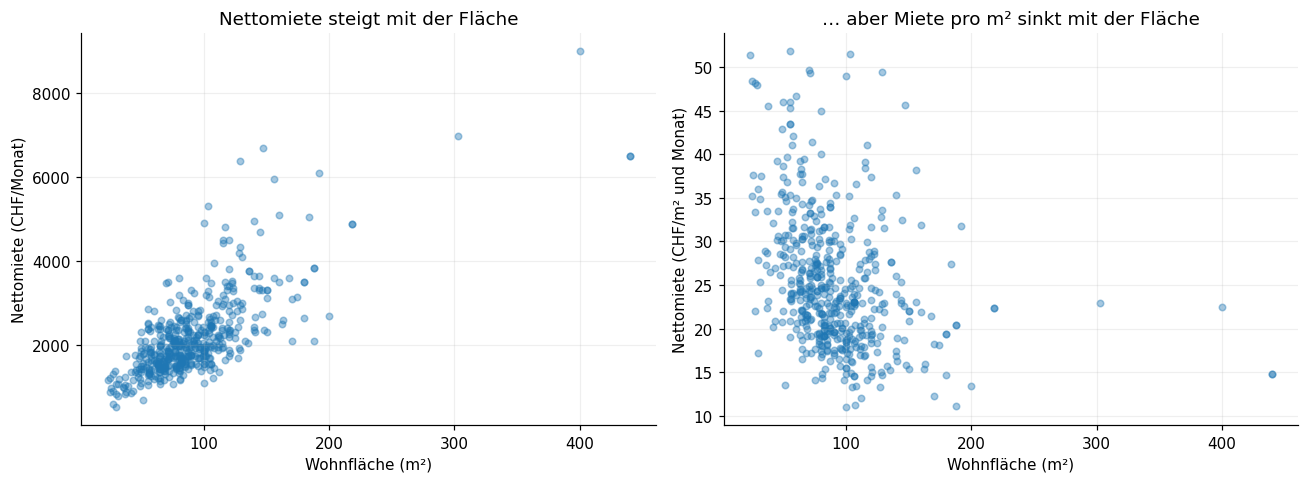

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(df["surface_living"], df["rent_net"], alpha=0.4, s=18)
axes[0].set(title="Nettomiete steigt mit der Fläche", xlabel="Wohnfläche (m²)", ylabel="Nettomiete (CHF/Monat)")

axes[1].scatter(df["surface_living"], df["rent_net_per_m2"], alpha=0.4, s=18)
axes[1].set(title="… aber Miete pro m² sinkt mit der Fläche", xlabel="Wohnfläche (m²)", ylabel="Nettomiete (CHF/m² und Monat)")

for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Interpretation:** Die Fläche erklärt den Gesamtpreis sehr stark, hängt aber negativ mit dem Preis pro m² zusammen (Grössendegression). Fläche und Zimmerzahl sind stark miteinander korreliert und messen weitgehend dasselbe. Das Baujahr ist nur für rund zwei Drittel der Inserate angegeben (222 von 332); es wird deshalb nicht als Kontrollvariable verwendet, weil sonst ein Drittel der Stichprobe wegfallen würde. Balkon/Garten hängt überraschend leicht negativ mit der Miete pro m² zusammen (nicht signifikant), vermutlich weil Wohnungen mit Balkon im Schnitt grösser sind.

## 4. Gemeindeindikatoren einzeln (Research Question 1)

**Wichtiger methodischer Punkt:** Die Gemeindeindikatoren haben pro Gemeinde nur einen Wert. Alle Inserate in Luzern haben dasselbe Einkommen. Würden wir einfach über alle Inserate korrelieren, würde die Stadt Luzern (rund ein Fünftel aller Inserate) das Ergebnis dominieren und die p-Werte wären zu optimistisch.

Darum rechnen wir die Korrelation auf **Gemeindeebene**: pro Gemeinde der Median der Miete pro m², dann Spearman-Korrelation mit dem Indikator. Gemeinden mit sehr wenigen Inseraten haben einen unsicheren Median; wir zeigen deshalb beide Varianten (alle Gemeinden / mind. 3 Inserate).

In [5]:
muni = (
    df.groupby("gemeinde_bfs")
    .agg(rent_per_m2_median=("rent_net_per_m2", "median"),
         n_listings=("pk", "size"),
         surface_median=("surface_living", "median"))
    .reset_index()
    .merge(gemeinden, on="gemeinde_bfs", how="left", validate="one_to_one")
)
print(f"Gemeinden mit Inseraten: {len(muni)}, davon mit mind. 3 Inseraten: {(muni['n_listings'] >= 3).sum()}")


def spearman_ci(x, y, alpha=0.05):
    # Spearman-rho mit Konfidenzintervall über Fisher-z-Transformation
    rho, p = stats.spearmanr(x, y)
    n = len(x)
    se = 1.06 / np.sqrt(n - 3)  # Korrektur für Spearman (Fieller et al. 1957)
    z = np.arctanh(rho)
    zc = stats.norm.ppf(1 - alpha / 2)
    return rho, p, np.tanh(z - zc * se), np.tanh(z + zc * se), n


rows = []
for col, label in INDICATORS.items():
    for name, data in [("alle Gemeinden", muni), ("mind. 3 Inserate", muni[muni["n_listings"] >= 3])]:
        sub = data[[col, "rent_per_m2_median"]].dropna()
        rho, p, lo, hi, n = spearman_ci(sub[col], sub["rent_per_m2_median"])
        rows.append({"Indikator": label, "Spalte": col, "Stichprobe": name,
                     "rho": rho, "CI 2.5%": lo, "CI 97.5%": hi, "p": p, "n Gemeinden": n})

muni_corr = pd.DataFrame(rows)
table_rq1 = (muni_corr[muni_corr["Stichprobe"] == "alle Gemeinden"]
             .sort_values("rho", key=abs, ascending=False)
             .drop(columns=["Spalte", "Stichprobe"]))
table_rq1

Gemeinden mit Inseraten: 98, davon mit mind. 3 Inseraten: 51


,Indikator,rho,CI 2.5%,CI 97.5%,p,n Gemeinden
0,"Medianeinkommen (CHF, 2022)",0.543,0.376,0.676,0.000,98
2,"Bevölkerungsdichte (log, Einw./km² prod. Fläche)",0.354,0.156,0.525,0.000,98
18,Mittlere Haushaltsgrösse,-0.308,-0.487,-0.105,0.002,98
10,Ausländeranteil (%),0.297,0.093,0.478,0.003,98
16,Anteil 65+ (%),0.237,0.029,0.426,0.019,98
14,Sozialhilfequote (%),-0.143,-0.347,0.074,0.170,94
4,Beschäftigte pro 100 Einw.,0.123,-0.089,0.324,0.228,98
12,Leerwohnungsziffer (%),-0.111,-0.313,0.102,0.278,98
22,Neubauwohnungen pro 1000 Einw.,0.061,-0.151,0.268,0.550,98
6,Bevölkerungswachstum 2024–25 (%),-0.057,-0.264,0.154,0.575,98


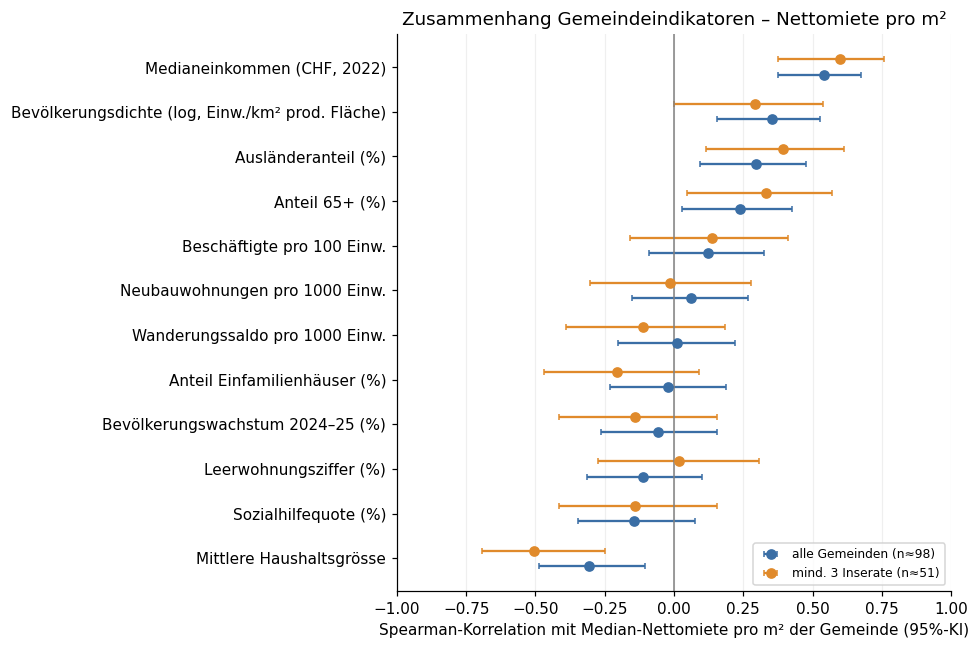

In [6]:
plot = muni_corr.copy()
order = (plot[plot["Stichprobe"] == "alle Gemeinden"]
         .sort_values("rho")["Indikator"].tolist())

fig, ax = plt.subplots(figsize=(9, 6))
offsets = {"alle Gemeinden": -0.17, "mind. 3 Inserate": 0.17}
colors = {"alle Gemeinden": "#3a6ea5", "mind. 3 Inserate": "#e08a2b"}

for name, g in plot.groupby("Stichprobe"):
    g = g.set_index("Indikator").loc[order]
    y = np.arange(len(order)) + offsets[name]
    n = int(g["n Gemeinden"].max())
    ax.errorbar(g["rho"], y, xerr=[g["rho"] - g["CI 2.5%"], g["CI 97.5%"] - g["rho"]],
                fmt="o", color=colors[name], capsize=2, label=f"{name} (n≈{n})")

ax.axvline(0, color="grey", lw=1)
ax.set_yticks(np.arange(len(order)), order)
ax.set(xlabel="Spearman-Korrelation mit Median-Nettomiete pro m² der Gemeinde (95%-KI)",
       title="Zusammenhang Gemeindeindikatoren – Nettomiete pro m²", xlim=(-1, 1))
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

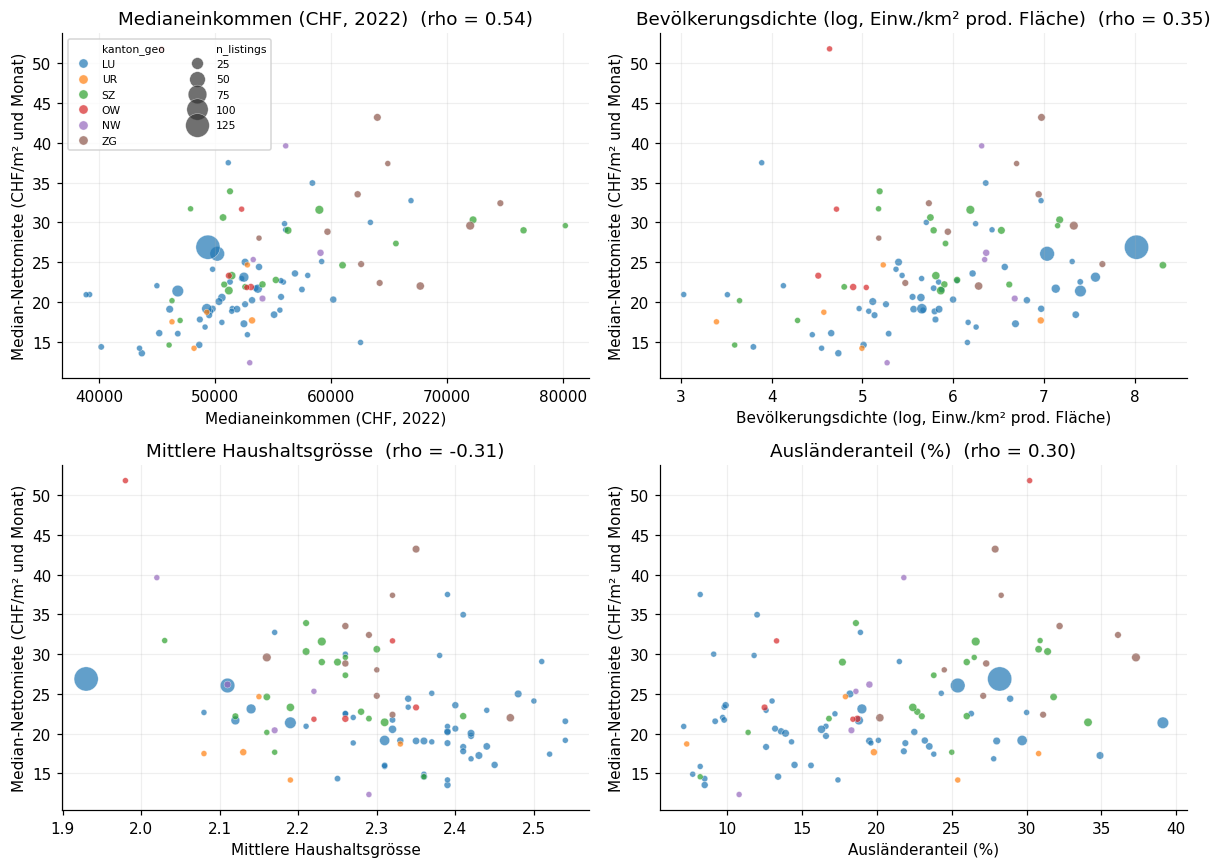

In [7]:
# Die vier stärksten Indikatoren im Streudiagramm (Punktgrösse = Anzahl Inserate)
top4 = table_rq1.head(4)["Indikator"].tolist()
label_to_col = {v: k for k, v in INDICATORS.items()}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, label in zip(axes.ravel(), top4):
    col = label_to_col[label]
    sns.scatterplot(data=muni, x=col, y="rent_per_m2_median", hue="kanton_geo",
                    size="n_listings", sizes=(15, 250), alpha=0.7, ax=ax, legend=(ax is axes[0, 0]))
    rho = table_rq1.set_index("Indikator").loc[label, "rho"]
    ax.set(title=f"{label}  (rho = {rho:.2f})", xlabel=label, ylabel="Median-Nettomiete (CHF/m² und Monat)")
    ax.grid(alpha=0.2)

axes[0, 0].legend(fontsize=7, loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

### Zusammenhänge zwischen den Indikatoren

Viele Indikatoren messen ähnliche Dinge (Stadt vs. Land). Die folgende Matrix zeigt, welche Indikatoren stark miteinander korrelieren. Das ist wichtig für RQ2: Stark korrelierte Variablen lassen sich in einer gemeinsamen Regression kaum auseinanderhalten.

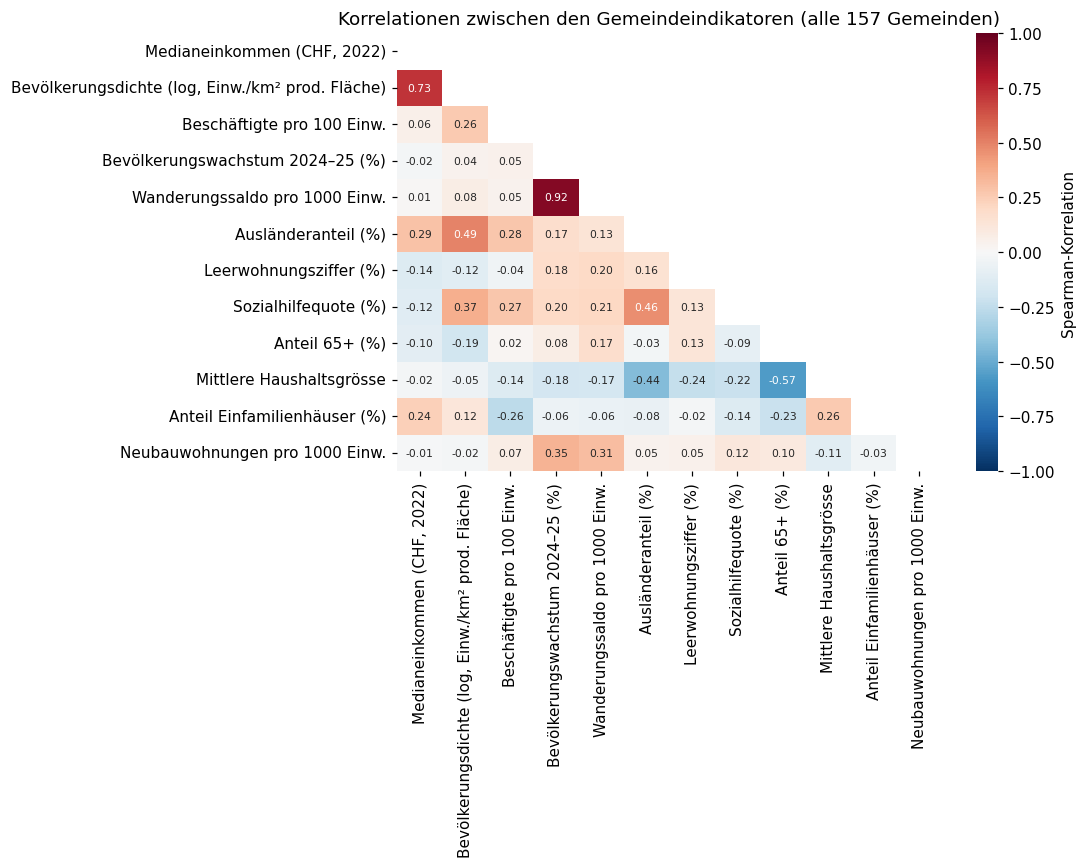

In [8]:
corr_matrix = gemeinden[list(INDICATORS)].rename(columns=INDICATORS).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws={"size": 7}, cbar_kws={"label": "Spearman-Korrelation"}, ax=ax)
ax.set_title("Korrelationen zwischen den Gemeindeindikatoren (alle 157 Gemeinden)")
plt.tight_layout()
plt.show()

## 5. Indikatoren unter Kontrolle der Wohnungsmerkmale (Research Question 2)

Jetzt auf Ebene der Inserate, mit einer linearen Regression:

$$\log(\text{Nettomiete pro m}^2) = \beta_0 + \beta_1 \log(\text{Fläche}) + \beta_2 \,\text{Zimmer} + \beta_3\,\text{Balkon} + \beta_4\,\text{Lift} + \gamma \cdot z(\text{Indikator}) + \varepsilon$$

- **log-Miete:** Der Koeffizient γ lässt sich als ungefähre prozentuale Veränderung lesen: Miete pro m² steigt um ca. 100·γ % pro Standardabweichung des Indikators.
- **Standardisierte Indikatoren (z-Werte):** Dadurch sind die Koeffizienten zwischen den Indikatoren vergleichbar.
- **Cluster-robuste Standardfehler nach Gemeinde:** Inserate in derselben Gemeinde teilen den Indikatorwert und sind nicht unabhängig. Ohne diese Korrektur wären die Konfidenzintervalle viel zu schmal.

Weil die Indikatoren stark untereinander korrelieren, schätzen wir zuerst jeden Indikator einzeln (jeweils mit den Wohnungs-Kontrollen). Danach testen wir ein gemeinsames Modell.

In [9]:
CONTROLS = "log_surface + number_of_rooms + has_balcony + has_lift"

reg = df.copy()
for col in INDICATORS:
    reg[f"z_{col}"] = (reg[col] - reg[col].mean()) / reg[col].std()


def fit_clustered(formula, data):
    data = data.dropna(subset=[c for c in data.columns if c in formula])
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["gemeinde_bfs"]}), data


base_model, base_data = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS}", reg)
print(f"Nur Wohnungsmerkmale: R² = {base_model.rsquared:.3f}, n = {int(base_model.nobs)}")
base_model.summary().tables[1]

Nur Wohnungsmerkmale: R² = 0.218, n = 510


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,4.5945,0.252,18.234,0.000,4.101,5.088
log_surface,-0.3404,0.067,-5.076,0.000,-0.472,-0.209
number_of_rooms,0.0183,0.021,0.858,0.391,-0.023,0.060
has_balcony,-0.0441,0.025,-1.799,0.072,-0.092,0.004
has_lift,0.1266,0.027,4.726,0.000,0.074,0.179


In [10]:
rows = []
for col, label in INDICATORS.items():
    model, data = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS} + z_{col}", reg)
    # R² des Basismodells auf denselben Beobachtungen (wegen fehlender Werte)
    base_same, _ = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS}", data)
    lo, hi = model.conf_int().loc[f"z_{col}"]
    rows.append({
        "Indikator": label,
        "Effekt pro SD (%)": 100 * (np.exp(model.params[f"z_{col}"]) - 1),
        "KI 2.5% (%)": 100 * (np.exp(lo) - 1),
        "KI 97.5% (%)": 100 * (np.exp(hi) - 1),
        "p (cluster)": model.pvalues[f"z_{col}"],
        "R² Zuwachs": model.rsquared - base_same.rsquared,
        "n": int(model.nobs),
    })

table_rq2 = pd.DataFrame(rows).sort_values("R² Zuwachs", ascending=False).reset_index(drop=True)
table_rq2

,Indikator,Effekt pro SD (%),KI 2.5% (%),KI 97.5% (%),p (cluster),R² Zuwachs,n
0,"Medianeinkommen (CHF, 2022)",11.294,6.987,15.775,0.000,0.132,510
1,"Bevölkerungsdichte (log, Einw./km² prod. Fläche)",7.490,4.396,10.677,0.000,0.060,510
2,Mittlere Haushaltsgrösse,-6.524,-9.640,-3.300,0.000,0.051,510
3,Ausländeranteil (%),5.730,-0.298,12.123,0.063,0.036,510
4,Beschäftigte pro 100 Einw.,5.617,1.939,9.428,0.003,0.035,510
5,Anteil 65+ (%),5.177,1.674,8.800,0.003,0.030,510
6,Leerwohnungsziffer (%),-4.213,-7.024,-1.316,0.005,0.022,510
7,Anteil Einfamilienhäuser (%),-4.181,-6.810,-1.478,0.003,0.021,510
8,Bevölkerungswachstum 2024–25 (%),-2.461,-6.316,1.552,0.226,0.007,510
9,Sozialhilfequote (%),2.054,-2.126,6.412,0.341,0.005,505


In [11]:
# Vergleich: Rangfolge FF1 (einzeln) vs. FF2 (mit Kontrollen)
ranking = (
    table_rq1[["Indikator", "rho"]]
    .assign(**{"Rang FF1": lambda t: t["rho"].abs().rank(ascending=False).astype(int)})
    .merge(table_rq2[["Indikator", "Effekt pro SD (%)", "R² Zuwachs"]], on="Indikator")
    .assign(**{"Rang FF2": lambda t: t["R² Zuwachs"].rank(ascending=False).astype(int)})
    .sort_values("Rang FF2")
)
ranking

,Indikator,rho,Rang FF1,Effekt pro SD (%),R² Zuwachs,Rang FF2
0,"Medianeinkommen (CHF, 2022)",0.543,1,11.294,0.132,1
1,"Bevölkerungsdichte (log, Einw./km² prod. Fläche)",0.354,2,7.490,0.060,2
2,Mittlere Haushaltsgrösse,-0.308,3,-6.524,0.051,3
3,Ausländeranteil (%),0.297,4,5.730,0.036,4
6,Beschäftigte pro 100 Einw.,0.123,7,5.617,0.035,5
4,Anteil 65+ (%),0.237,5,5.177,0.030,6
7,Leerwohnungsziffer (%),-0.111,8,-4.213,0.022,7
10,Anteil Einfamilienhäuser (%),-0.023,11,-4.181,0.021,8
9,Bevölkerungswachstum 2024–25 (%),-0.057,10,-2.461,0.007,9
5,Sozialhilfequote (%),-0.143,6,2.054,0.005,10


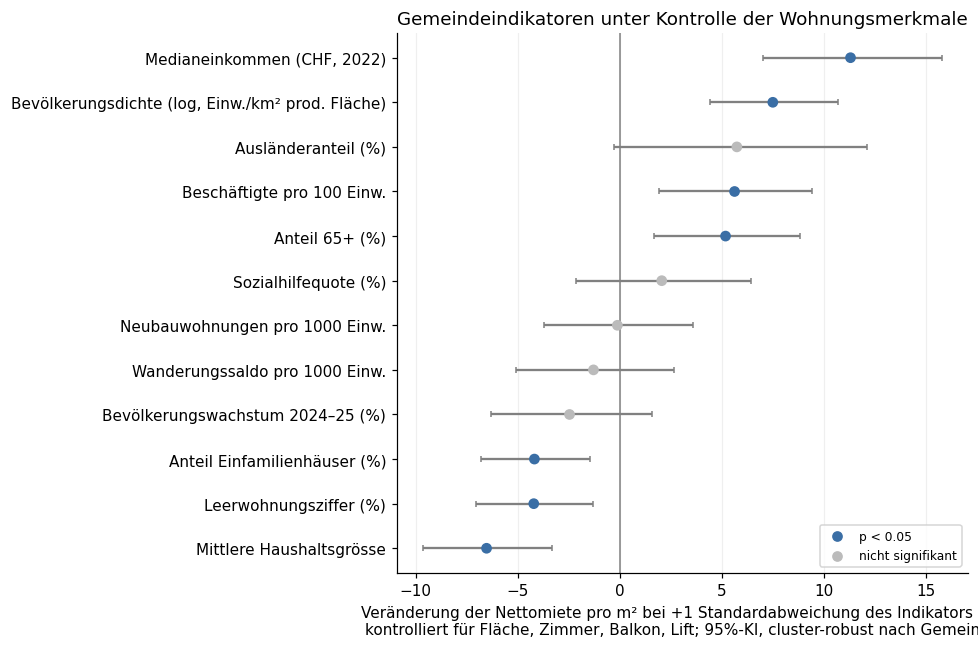

In [12]:
plot = table_rq2.sort_values("Effekt pro SD (%)")
fig, ax = plt.subplots(figsize=(9, 6))
significant = plot["p (cluster)"] < 0.05
ax.errorbar(plot["Effekt pro SD (%)"], plot["Indikator"],
            xerr=[plot["Effekt pro SD (%)"] - plot["KI 2.5% (%)"], plot["KI 97.5% (%)"] - plot["Effekt pro SD (%)"]],
            fmt="none", ecolor="grey", capsize=2)
ax.scatter(plot["Effekt pro SD (%)"], plot["Indikator"], c=np.where(significant, "#3a6ea5", "#bbbbbb"), zorder=3)
ax.axvline(0, color="grey", lw=1)
ax.set(xlabel="Veränderung der Nettomiete pro m² bei +1 Standardabweichung des Indikators (%)\n"
              "kontrolliert für Fläche, Zimmer, Balkon, Lift; 95%-KI, cluster-robust nach Gemeinde",
       title="Gemeindeindikatoren unter Kontrolle der Wohnungsmerkmale")
ax.grid(axis="x", alpha=0.2)
ax.scatter([], [], c="#3a6ea5", label="p < 0.05")
ax.scatter([], [], c="#bbbbbb", label="nicht signifikant")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### Gemeinsames Modell

Alle Indikatoren gleichzeitig ins Modell zu nehmen ist problematisch, wenn sie stark korrelieren (Multikollinearität). Wir prüfen das mit dem Variance Inflation Factor (VIF): Werte über ca. 5 bedeuten, dass ein Indikator grösstenteils durch die anderen erklärt wird und sein Koeffizient unzuverlässig ist.

In [13]:
full_cols = list(INDICATORS)
X = reg[[f"z_{c}" for c in full_cols]].dropna()
vif = pd.DataFrame({
    "Indikator": [INDICATORS[c] for c in full_cols],
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
}).sort_values("VIF", ascending=False)
vif

,Indikator,VIF
3,Bevölkerungswachstum 2024–25 (%),20.433
4,Wanderungssaldo pro 1000 Einw.,19.653
7,Sozialhilfequote (%),9.138
9,Mittlere Haushaltsgrösse,8.767
1,"Bevölkerungsdichte (log, Einw./km² prod. Fläche)",4.990
10,Anteil Einfamilienhäuser (%),4.986
0,"Medianeinkommen (CHF, 2022)",3.006
2,Beschäftigte pro 100 Einw.,2.310
5,Ausländeranteil (%),1.973
8,Anteil 65+ (%),1.971


In [14]:
# Reduziertes Modell: Indikatoren mit VIF > 5 schrittweise entfernen (jeweils den höchsten)
selected = list(full_cols)
while True:
    X = reg[[f"z_{c}" for c in selected]].dropna()
    v = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=selected)
    if v.max() <= 5:
        break
    print(f"entfernt: {INDICATORS[v.idxmax()]} (VIF {v.max():.1f})")
    selected.remove(v.idxmax())

formula = f"log_rent_per_m2 ~ {CONTROLS} + " + " + ".join(f"z_{c}" for c in selected)
joint_model, joint_data = fit_clustered(formula, reg)
print(f"\nGemeinsames Modell: R² = {joint_model.rsquared:.3f}, adj. R² = {joint_model.rsquared_adj:.3f}, "
      f"n = {int(joint_model.nobs)}, Gemeinden = {joint_data['gemeinde_bfs'].nunique()}")

joint = pd.DataFrame({
    "Effekt pro SD (%)": 100 * (np.exp(joint_model.params) - 1),
    "p (cluster)": joint_model.pvalues,
}).loc[[f"z_{c}" for c in selected]]
joint.index = [INDICATORS[c] for c in selected]
joint.sort_values("p (cluster)")

entfernt: Bevölkerungswachstum 2024–25 (%) (VIF 20.4)


entfernt: Sozialhilfequote (%) (VIF 9.1)
entfernt: Mittlere Haushaltsgrösse (VIF 7.0)

Gemeinsames Modell: R² = 0.444, adj. R² = 0.429, n = 510, Gemeinden = 98


,Effekt pro SD (%),p (cluster)
"Medianeinkommen (CHF, 2022)",11.304,0.000
Anteil 65+ (%),3.602,0.026
"Bevölkerungsdichte (log, Einw./km² prod. Fläche)",3.815,0.065
Anteil Einfamilienhäuser (%),-4.037,0.096
Leerwohnungsziffer (%),-1.859,0.200
Ausländeranteil (%),2.838,0.205
Neubauwohnungen pro 1000 Einw.,0.802,0.553
Beschäftigte pro 100 Einw.,-0.861,0.629
Wanderungssaldo pro 1000 Einw.,0.028,0.984


### Robustheitsprüfung

Zwei Prüfungen, ob die Ergebnisse von Entscheidungen bei der Bereinigung abhängen:

1. **Bruttomiete statt Nettomiete:** Die Nettomiete wurde für einen Teil der Inserate aus Bruttomiete − Nebenkosten berechnet. Mit der Bruttomiete als Zielgrösse sollten Richtung und Rangfolge ähnlich bleiben.
2. **Nur direkt angegebene Nettomieten:** Die berechneten Nettomieten werden weggelassen.

Wenn die Effekte in allen Varianten ähnlich sind, hängen die Schlussfolgerungen nicht von diesen Entscheidungen ab.

In [15]:
variants = {
    "Bruttomiete": reg.assign(
        log_rent_per_m2=np.log(reg["rent_gross"].fillna(reg["rent_net"] + reg["rent_charges"]) / reg["surface_living"])
    ),
    "nur angegebene Nettomiete": reg[reg["rent_net_source"] == "angegeben"],
}

robust = table_rq2[["Indikator", "Effekt pro SD (%)", "p (cluster)"]].copy()
for name, data in variants.items():
    rows = []
    for col, label in INDICATORS.items():
        model, _ = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS} + z_{col}", data)
        rows.append({"Indikator": label,
                     f"Effekt (%) {name}": 100 * (np.exp(model.params[f"z_{col}"]) - 1),
                     f"p {name}": model.pvalues[f"z_{col}"],
                     f"n {name}": int(model.nobs)})
    robust = robust.merge(pd.DataFrame(rows), on="Indikator")
    agreement = stats.spearmanr(robust["Effekt pro SD (%)"], robust[f"Effekt (%) {name}"])[0]
    print(f"Übereinstimmung der Rangfolge Nettomiete vs. {name}: {agreement:.2f}")

robust

Übereinstimmung der Rangfolge Nettomiete vs. Bruttomiete: 0.99
Übereinstimmung der Rangfolge Nettomiete vs. nur angegebene Nettomiete: 0.98


,Indikator,Effekt pro SD (%),p (cluster),Effekt (%) Bruttomiete,p Bruttomiete,n Bruttomiete,Effekt (%) nur angegebene Nettomiete,p nur angegebene Nettomiete,n nur angegebene Nettomiete
0,"Medianeinkommen (CHF, 2022)",11.294,0.000,11.058,0.000,501,10.739,0.000,435
1,"Bevölkerungsdichte (log, Einw./km² prod. Fläche)",7.490,0.000,6.736,0.000,501,7.942,0.000,435
2,Mittlere Haushaltsgrösse,-6.524,0.000,-5.825,0.001,501,-7.075,0.000,435
3,Ausländeranteil (%),5.730,0.063,5.775,0.034,501,5.952,0.058,435
4,Beschäftigte pro 100 Einw.,5.617,0.003,4.957,0.004,501,5.926,0.003,435
5,Anteil 65+ (%),5.177,0.003,5.227,0.001,501,5.743,0.001,435
6,Leerwohnungsziffer (%),-4.213,0.005,-3.695,0.004,501,-3.031,0.108,435
7,Anteil Einfamilienhäuser (%),-4.181,0.003,-3.458,0.005,501,-4.510,0.006,435
8,Bevölkerungswachstum 2024–25 (%),-2.461,0.226,-2.323,0.229,501,-3.125,0.140,435
9,Sozialhilfequote (%),2.054,0.341,1.407,0.452,496,3.303,0.138,434


## 6. Stadt und Land im Vergleich (Research Question 3)

**Frage:** Gelten die Zusammenhänge aus RQ1 und RQ2 gleichermassen in städtischen und ländlichen Gemeinden, oder unterscheiden sich Stärke und Rangfolge der Indikatoren?

**Einteilung:** offizielle **Stadt/Land-Typologie des BFS** (Gemeindetypologie 2020, Gemeindestand 01.01.2026; Datei `data/demographic_data/raumgliederungen_bfs.xlsx`, exportiert aus dem Historisierten Gemeindeverzeichnis des BFS). Sie unterscheidet städtisch, intermediär (dichter periurbaner Raum und ländliche Zentren) und ländlich. Intermediäre und ländliche Gemeinden haben in unserer Stichprobe je nur 55 Wohnungen; für den Vergleich fassen wir sie deshalb zu „intermediär/ländlich“ zusammen und vergleichen sie mit den städtischen Gemeinden.

**Einschränkung:** Die Gruppe intermediär/ländlich ist mit rund 110 Wohnungen deutlich kleiner als die städtische. Das heisst, ihre Ergebnisse sind entsprechend unsicherer.

In [16]:
TYPOLOGY_FILE = PROJECT_DIR / "data" / "demographic_data" / "raumgliederungen_bfs.xlsx"

# Blatt "Daten": Zeile 2 enthält die Spaltennamen, Zeile 3 die Codelisten-IDs (überspringen)
typology = pd.read_excel(TYPOLOGY_FILE, sheet_name="Daten", header=1, skiprows=[2])
typology = typology.rename(columns={"BFS Gde-nummer": "gemeinde_bfs", "Stadt/Land-Typologie": "stadt_land_code"})
typology["stadt_land"] = typology["stadt_land_code"].map({1: "städtisch", 2: "intermediär", 3: "ländlich"})
typology["urban_rural"] = typology["stadt_land"].replace({"intermediär": "intermediär/ländlich", "ländlich": "intermediär/ländlich"})

reg = reg.drop(columns=["stadt_land", "urban_rural"], errors="ignore").merge(
    typology[["gemeinde_bfs", "stadt_land", "urban_rural"]], on="gemeinde_bfs", how="left", validate="many_to_one")
assert reg["urban_rural"].notna().all(), "Gemeinde ohne Stadt/Land-Typologie"

print("Alle Gemeinden der Zentralschweiz nach Typologie:")
display(gemeinden.merge(typology[["gemeinde_bfs", "stadt_land"]], on="gemeinde_bfs", how="left")["stadt_land"].value_counts())

GROUPS = ["städtisch", "intermediär/ländlich"]
overview = reg.groupby("stadt_land").agg(
    Wohnungen=("pk", "size"),
    Gemeinden=("gemeinde_bfs", "nunique"),
    Median_Nettomiete_pro_m2=("rent_net_per_m2", "median"),
    Median_Fläche=("surface_living", "median"),
).reindex(["städtisch", "intermediär", "ländlich"])
overview

Alle Gemeinden der Zentralschweiz nach Typologie:


stadt_land
ländlich       75
städtisch      42
intermediär    40
Name: count, dtype: int64

,Wohnungen,Gemeinden,Median_Nettomiete_pro_m2,Median_Fläche
stadt_land,,,,
städtisch,346,38,25.557,80.000
intermediär,88,30,20.774,91.000
ländlich,76,30,19.357,97.500


In [17]:
RQ3_INDICATORS = INDICATORS

# FF1 je Gruppe: Spearman auf Gemeindeebene
muni_groups = muni.merge(reg.groupby("gemeinde_bfs")["urban_rural"].first().reset_index(), on="gemeinde_bfs")

rows = []
for group in GROUPS:
    data = muni_groups[muni_groups["urban_rural"] == group]
    for col, label in RQ3_INDICATORS.items():
        sub = data[[col, "rent_per_m2_median"]].dropna()
        rho, p, lo, hi, n = spearman_ci(sub[col], sub["rent_per_m2_median"])
        rows.append({"Indikator": label, "Gruppe": group, "rho": rho, "p": p, "n Gemeinden": n})
rq3_corr = pd.DataFrame(rows).pivot(index="Indikator", columns="Gruppe", values=["rho", "p"])
rq3_corr.columns = [f"{a} {b}" for a, b in rq3_corr.columns]
rq3_corr = rq3_corr[["rho städtisch", "p städtisch", "rho intermediär/ländlich", "p intermediär/ländlich"]].sort_values("rho städtisch", key=abs, ascending=False)
rq3_corr

,rho städtisch,p städtisch,rho intermediär/ländlich,p intermediär/ländlich
Indikator,,,,
"Medianeinkommen (CHF, 2022)",0.408,0.011,0.545,0.000
Ausländeranteil (%),0.261,0.114,0.101,0.441
Beschäftigte pro 100 Einw.,0.200,0.229,-0.157,0.232
Sozialhilfequote (%),-0.179,0.281,-0.390,0.003
Leerwohnungsziffer (%),-0.156,0.350,0.006,0.965
Anteil 65+ (%),-0.121,0.470,0.292,0.023
Bevölkerungswachstum 2024–25 (%),-0.073,0.661,0.021,0.873
Neubauwohnungen pro 1000 Einw.,0.056,0.739,0.170,0.193
Anteil Einfamilienhäuser (%),-0.047,0.777,0.079,0.548


In [18]:
# FF2 je Gruppe: Einzelmodelle mit Wohnungs-Kontrollen, cluster-robust nach Gemeinde
rows = []
for group in GROUPS:
    data = reg[reg["urban_rural"] == group].copy()
    # z-Werte innerhalb der Gruppe, damit "1 SD" die Streuung in der Gruppe meint
    for col in RQ3_INDICATORS:
        data[f"zg_{col}"] = (data[col] - data[col].mean()) / data[col].std()
    for col, label in RQ3_INDICATORS.items():
        if data[col].nunique() < 3:
            continue
        model, used = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS} + zg_{col}", data)
        lo, hi = model.conf_int().loc[f"zg_{col}"]
        rows.append({"Indikator": label, "Gruppe": group,
                     "Effekt (%)": 100 * (np.exp(model.params[f"zg_{col}"]) - 1),
                     "KI 2.5% (%)": 100 * (np.exp(lo) - 1), "KI 97.5% (%)": 100 * (np.exp(hi) - 1),
                     "p": model.pvalues[f"zg_{col}"], "n": int(model.nobs),
                     "Gemeinden": used["gemeinde_bfs"].nunique()})

rq3_reg = pd.DataFrame(rows)
rq3_wide = rq3_reg.pivot(index="Indikator", columns="Gruppe", values=["Effekt (%)", "p"])
rq3_wide.columns = [f"{a} {b}" for a, b in rq3_wide.columns]
rq3_wide = rq3_wide[["Effekt (%) städtisch", "p städtisch", "Effekt (%) intermediär/ländlich", "p intermediär/ländlich"]]

rank_corr_rho = stats.spearmanr(rq3_corr["rho städtisch"], rq3_corr["rho intermediär/ländlich"])[0]
rank_corr_reg = stats.spearmanr(rq3_wide["Effekt (%) städtisch"], rq3_wide["Effekt (%) intermediär/ländlich"])[0]
print(f"Übereinstimmung der Rangfolge städtisch vs. intermediär/ländlich – Korrelationen (FF1): {rank_corr_rho:.2f}")
print(f"Übereinstimmung der Rangfolge städtisch vs. intermediär/ländlich – Regressionseffekte (FF2): {rank_corr_reg:.2f}")
rq3_wide.sort_values("Effekt (%) städtisch")

Übereinstimmung der Rangfolge städtisch vs. intermediär/ländlich – Korrelationen (FF1): 0.45
Übereinstimmung der Rangfolge städtisch vs. intermediär/ländlich – Regressionseffekte (FF2): 0.52


,Effekt (%) städtisch,p städtisch,Effekt (%) intermediär/ländlich,p intermediär/ländlich
Indikator,,,,
Leerwohnungsziffer (%),-5.179,0.036,-2.511,0.059
Sozialhilfequote (%),-3.870,0.121,-5.971,0.012
Bevölkerungswachstum 2024–25 (%),-2.382,0.196,-3.266,0.145
Wanderungssaldo pro 1000 Einw.,-1.789,0.396,-2.911,0.170
"Bevölkerungsdichte (log, Einw./km² prod. Fläche)",-1.315,0.423,4.300,0.129
Neubauwohnungen pro 1000 Einw.,-0.471,0.889,2.700,0.176
Anteil Einfamilienhäuser (%),-0.436,0.793,1.829,0.512
Ausländeranteil (%),-0.025,0.994,2.988,0.442
Mittlere Haushaltsgrösse,0.886,0.681,-7.156,0.008


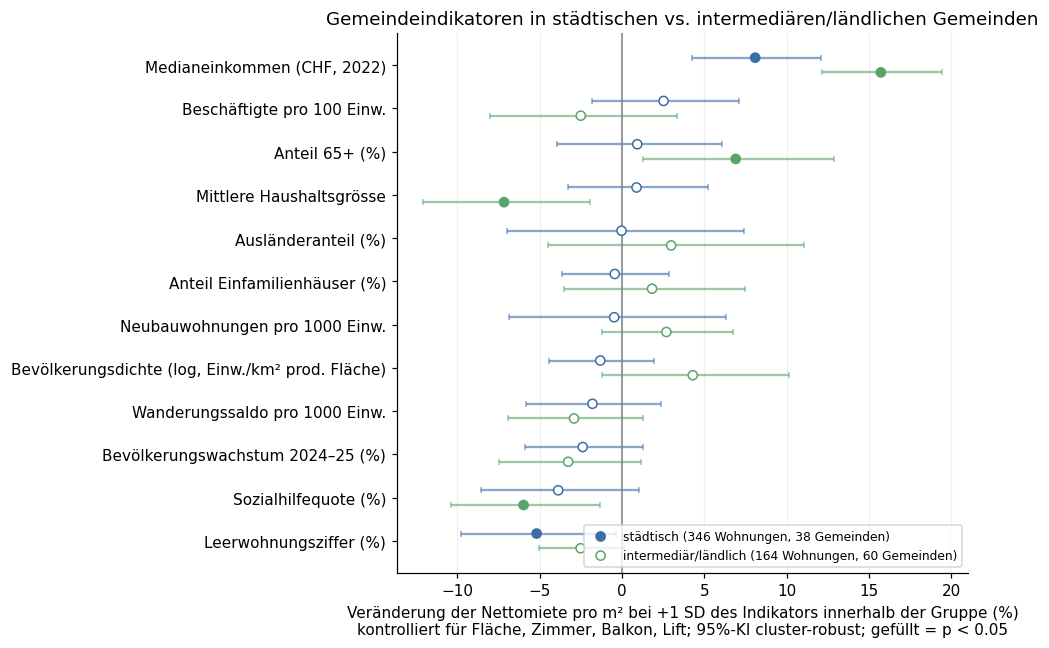

In [19]:
order = rq3_wide.sort_values("Effekt (%) städtisch").index.tolist()
colors = {"städtisch": "#3a6ea5", "intermediär/ländlich": "#5aa469"}
offsets = {"städtisch": 0.17, "intermediär/ländlich": -0.17}

fig, ax = plt.subplots(figsize=(9, 6))
for group in GROUPS:
    g = rq3_reg[rq3_reg["Gruppe"] == group].set_index("Indikator").reindex(order)
    y = np.arange(len(order)) + offsets[group]
    sig = g["p"] < 0.05
    ax.errorbar(g["Effekt (%)"], y, xerr=[g["Effekt (%)"] - g["KI 2.5% (%)"], g["KI 97.5% (%)"] - g["Effekt (%)"]],
                fmt="none", ecolor=colors[group], alpha=0.6, capsize=2)
    ax.scatter(g["Effekt (%)"], y, facecolors=np.where(sig, colors[group], "white"), edgecolors=colors[group], zorder=3,
               label=f"{group} ({int(g['n'].max())} Wohnungen, {int(g['Gemeinden'].max())} Gemeinden)")
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(np.arange(len(order)), order)
ax.set(xlabel="Veränderung der Nettomiete pro m² bei +1 SD des Indikators innerhalb der Gruppe (%)\n"
              "kontrolliert für Fläche, Zimmer, Balkon, Lift; 95%-KI cluster-robust; gefüllt = p < 0.05",
       title="Gemeindeindikatoren in städtischen vs. intermediären/ländlichen Gemeinden")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretation RQ3

- **Mietniveau:** Die Nettomiete pro m² sinkt von städtischen (Median CHF 26.4) über intermediäre (21.6) zu ländlichen Gemeinden (19.1).

- **Stabil:** Das Medianeinkommen ist in beiden Gruppen der stärkste Indikator (städtisch +8.1 %, intermediär/ländlich +15.9 % pro Standardabweichung innerhalb der Gruppe). Auch Leerwohnungsziffer (−6.2 % / −3.8 %) und Sozialhilfequote (−5.1 % / −5.2 %) hängen in beiden Gruppen negativ mit der Miete zusammen.

- **Nicht stabil:** Bevölkerungsdichte und Neubautätigkeit sind nur in intermediären/ländlichen Gemeinden mit höheren Mieten verbunden (+6.7 % bzw. +6.0 %); innerhalb der Städte spielt die Dichte keine erkennbare Rolle mehr. Haushaltsgrösse, Beschäftigte, Ausländeranteil und Anteil 65+ sind in keiner Gruppe signifikant: Ihr Zusammenhang in RQ1/RQ2 bildete vor allem den Unterschied zwischen Stadt und Land ab.

- **Sozialhilfequote:** In der Gesamtstichprobe ist sie leicht positiv (nicht signifikant), innerhalb beider Gruppen aber negativ. Städte haben zugleich höhere Mieten und höhere Sozialhilfequoten; erst innerhalb vergleichbarer Gemeinden zeigt sich der erwartete negative Zusammenhang.

- **Rangfolge:** Die Rangfolge der Indikatoren stimmt zwischen den Gruppen nur mässig überein (0.39 bei den Korrelationen, 0.43 bei den Regressionseffekten). Stabil ist vor allem die Spitze (Einkommen).

- **Vorsicht:** Die Gruppe intermediär/ländlich umfasst nur 110 Wohnungen in 51 Gemeinden, und die Wohnungsmerkmale erklären dort deutlich weniger (R² 0.13 gegenüber 0.32 in Städten). Die Ergebnisse für diese Gruppe sind entsprechend unsicher.

## 7. Zusammenfassung

Die Zahlen in diesem Abschnitt werden beim Ausführen automatisch aus den Tabellen oben erzeugt.

In [20]:
print("FF1 – stärkste Einzelzusammenhänge (Gemeindeebene, Spearman):")
for _, r in table_rq1.head(5).iterrows():
    sig = "signifikant" if r["p"] < 0.05 else "nicht signifikant"
    print(f"  {r['Indikator']:<50} rho = {r['rho']:+.2f}  ({sig})")

print("\nFF2 – mit Kontrolle der Wohnungsmerkmale (sortiert nach R²-Zuwachs):")
print(f"  Wohnungsmerkmale allein erklären R² = {base_model.rsquared:.2f}")
for _, r in table_rq2.head(5).iterrows():
    sig = "signifikant" if r["p (cluster)"] < 0.05 else "nicht signifikant"
    print(f"  {r['Indikator']:<50} {r['Effekt pro SD (%)']:+.1f}% pro SD, R²-Zuwachs {r['R² Zuwachs']:.3f}  ({sig})")

print(f"\nGemeinsames Modell (VIF <= 5): R² = {joint_model.rsquared:.2f}")

print("\nFF3 – städtisch vs. intermediär/ländlich (Rangfolge-Übereinstimmung):")
print(f"  Korrelationen: {rank_corr_rho:.2f}, Regressionseffekte: {rank_corr_reg:.2f}")
for group in GROUPS:
    top = rq3_reg[(rq3_reg["Gruppe"] == group)].sort_values("p").head(3)
    items = ", ".join(f"{r['Indikator']} ({r['Effekt (%)']:+.1f}%)" for _, r in top.iterrows())
    print(f"  {group}: {items}")

FF1 – stärkste Einzelzusammenhänge (Gemeindeebene, Spearman):
  Medianeinkommen (CHF, 2022)                        rho = +0.54  (signifikant)
  Bevölkerungsdichte (log, Einw./km² prod. Fläche)   rho = +0.35  (signifikant)
  Mittlere Haushaltsgrösse                           rho = -0.31  (signifikant)
  Ausländeranteil (%)                                rho = +0.30  (signifikant)
  Anteil 65+ (%)                                     rho = +0.24  (signifikant)

FF2 – mit Kontrolle der Wohnungsmerkmale (sortiert nach R²-Zuwachs):
  Wohnungsmerkmale allein erklären R² = 0.22
  Medianeinkommen (CHF, 2022)                        +11.3% pro SD, R²-Zuwachs 0.132  (signifikant)
  Bevölkerungsdichte (log, Einw./km² prod. Fläche)   +7.5% pro SD, R²-Zuwachs 0.060  (signifikant)
  Mittlere Haushaltsgrösse                           -6.5% pro SD, R²-Zuwachs 0.051  (signifikant)
  Ausländeranteil (%)                                +5.7% pro SD, R²-Zuwachs 0.036  (nicht signifikant)
  Beschäftigte pro 1

### Interpretation (Stand: Daten vom 18.–24.10.2026, 332 Wohnungen, 82 Gemeinden, Nettomiete)

**Wohnungsmerkmale:** Die Wohnfläche ist das stärkste Einzelmerkmal: Grosse Wohnungen kosten insgesamt mehr (rho = +0.63), pro m² aber weniger (rho = −0.44). Neuere bzw. kürzlich renovierte Wohnungen und höhere Stockwerke sind pro m² teurer. Fläche, Zimmer, Balkon und Lift zusammen erklären rund 24 % der Streuung der Nettomiete pro m².

**RQ1 – einzeln:** Am stärksten hängt die Nettomiete pro m² mit dem **Medianeinkommen** der Gemeinde zusammen (rho = +0.57). Danach folgen **Bevölkerungsdichte** (+0.36), **Ausländeranteil** (+0.28), **Haushaltsgrösse** (−0.26) und **Anteil 65+** (+0.24). Wachstum, Wanderungssaldo, Beschäftigte, Neubautätigkeit, Einfamilienhausanteil, Leerwohnungsziffer und Sozialhilfequote zeigen einzeln keinen signifikanten Zusammenhang.

**RQ2 – mit Kontrollen:** Das Einkommen bleibt klar an der Spitze (+11.6 % Nettomiete pro m² je Standardabweichung), gefolgt von Dichte (+8.0 %), Haushaltsgrösse (−6.3 %), **Leerwohnungsziffer** (−5.3 %) und Beschäftigten pro 100 Einw. (+5.4 %). Leerwohnungsziffer und Beschäftigte werden erst sichtbar, wenn die Wohnungsgrösse kontrolliert ist. Der Ausländeranteil verliert dagegen an Bedeutung (nicht mehr signifikant). Im gemeinsamen Modell (ohne kollineare Variablen) bleiben **Einkommen**, **Anteil 65+** und **Dichte** signifikant; die Gemeindeindikatoren erhöhen das R² von 0.24 auf 0.49.

**Vergleich mit den Hypothesen:**
- Bestätigt: Einkommen (+), Dichte (+), Beschäftigte (+, mit Kontrollen), Leerwohnungsziffer (−, mit Kontrollen), Haushaltsgrösse (−), Einfamilienhausanteil (−, mit Kontrollen).
- Nicht bestätigt: Bevölkerungswachstum und Wanderungssaldo zeigen keinen Zusammenhang. Möglicher Grund: Ein Jahr Wachstum (2024–25) ist eine sehr kurzfristige, schwankende Grösse.
- Entgegen der Erwartung: **Anteil 65+** ist positiv. Eine mögliche Erklärung sind wohlhabende Seegemeinden mit älterer Bevölkerung (z. B. am Vierwaldstättersee); das wäre noch zu prüfen.

**Robustheit:** Mit Bruttomiete statt Nettomiete (Übereinstimmung der Rangfolge 0.98) und nur mit direkt angegebenen Nettomieten (0.97) bleibt das Bild praktisch gleich.

**Vorsicht:** Einkommen, Dichte, Ausländeranteil und Beschäftigte messen alle zum Teil dasselbe (städtische, wirtschaftsstarke Lage). Welcher dieser Faktoren den Preis tatsächlich treibt, lässt sich mit Beobachtungsdaten nicht trennen.

**Einschränkungen**
- Zusammenhänge, keine Kausalität: Einkommen, Dichte und Ausländeranteil hängen alle mit „städtischer Lage“ zusammen. Welcher Faktor tatsächlich preistreibend ist, lässt sich mit diesen Daten nicht trennen.
- Die effektive Stichprobengrösse für Gemeindeindikatoren ist die Anzahl Gemeinden (82), nicht die Anzahl Inserate. Viele Gemeinden haben nur 1–3 Inserate.
- Die Stichprobe ist stark auf den Kanton Luzern konzentriert; Uri (3 Inserate), Obwalden (7) und Nidwalden (5) sind kaum vertreten, weil viele Inserate keine Nettomiete angeben.
- Inserate zeigen Angebotsmieten, nicht bezahlte Mieten, und nur Flatfox-Inserate in einer Woche im Oktober 2026.
- Nicht beobachtete Merkmale (Zustand, Mikrolage, Aussicht) können mit den Indikatoren zusammenhängen.